# <font color='teal'> Neural Networks from scratch </font>
### <font color='teal'> Deep Learning, part 1 of 3 </font>

    Notebook version: 1.0 (Oct 27, 2026)

    Authors: Jerónimo Arenas García (jarenas@ing.uc3m.es)
             Jesús Cid-Sueiro (jcid@tsc.uc3m.es)

    Changes: v.0.1. (Nov 14, 2020) - First version
             v.0.2. (Nov 5, 2021) - Structuring code, revisiting formulation
             v.0.3. (Nov, 1, 2022) - Revisiting text.
             v.0.4. (Nov, 4, 2024) - General notebook updates
             v.0.5. (Oct 27, 2025) - Typo correction. Support for different GPU architectures
             v.1.0. (Oct 27, 2026) - Split of the original notebook into three notebooks,
                                     one per session. This is part 1 (numpy only).
                                     Corrected the gradient of the hidden layer in the
                                     2-layer network (see Section 3.3). Numerically stable
                                     softmax. Normalization is now fit on the training
                                     partition only. Reproducible initialization.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

size = 14
params = {'legend.fontsize': 'Large',
          'axes.labelsize': size,
          'axes.titlesize': size,
          'xtick.labelsize': size*0.75,
          'ytick.labelsize': size*0.75}
plt.rcParams.update(params)

# Fix the seed so that results are reproducible from run to run
rng = np.random.default_rng(42)

## <font color='teal'> 1. Introduction and purpose of this Notebook </font>

### <font color='teal'> 1.1. About Neural Networks </font>

* Neural Networks (NN) have become the state of the art for many machine learning problems
    * Natural Language Processing
    * Computer Vision
    * Image Recognition

* They are in widespread use for many applications, e.g.,
    * Language translation
    * Automatic speech recognition (<a href="https://machinelearning.apple.com/research/hey-siri">Hey Siri!</a> DNN overview)
    * Autonomous navigation (<a href="https://venturebeat.com/2020/04/13/facebooks-ai-teaches-robots-to-navigate-environments-using-less-data/">Facebook Robot Autonomous 3D Navigation</a>)
    * Automatic plate recognition
    
<center>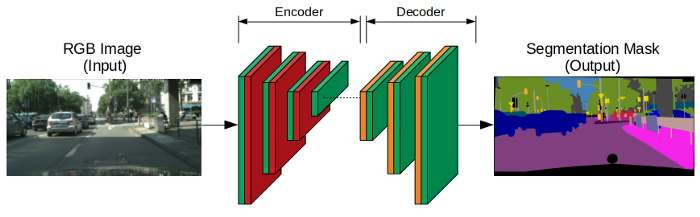</center>
    

Feed Forward Neural Networks [have been around since 1960](https://www.skynettoday.com/overviews/neural-net-history) but only recently (last 10-15 years) have they met their expectations, and improve other machine learning algorithms

* Computation resources are now available at large scale
* Cloud Computing (AWS, Azure)
* From MultiLayer Perceptrons to Deep Learning
* Big Data sets
* This has also made possible an intense research effort resulting in
    * Topologies better suited to particular problems (CNNs, RNNs, Transformers, Attention)
    * New training strategies providing better generalization

In parallel, Deep Learning Platforms have emerged that make design, implementation, training, and production of DNNs feasible for everyone

### <font color='teal'> 1.2. Scope of this notebook</font>

* To provide just an overview of the most important NN and DNN concepts
* Connecting with already studied methods as a starting point (mainly logistic regression)
* To set the basis for learning about more advanced topologies for Natural Language Processing

This is the **first of three notebooks** covering neural networks:

1. **Neural networks from scratch** (this notebook). Everything is implemented with
   numpy, so that no new library has to be learnt and every computation is explicit.
2. **Deep networks with PyTorch**. The same models, written with a library that
   computes the gradients for us, plus optimization and generalization.
3. **Convolutional neural networks**. Topologies specialized in images, and transfer
   learning.

### <font color='teal'> 1.3. Outline</font>

1. Introduction and purpose of this notebook
2. Datasets
3. Introduction to Neural Networks
    * 3.1. A single-layer NN for binary classification
    * 3.2. A single-layer NN for multiclass classification
    * 3.3. Multi-layer networks and back-propagation
    * 3.4. Activation functions
    * 3.5. Multi-layer networks for regression

### <font color='teal'> 1.4. Other resources </font>

* We point here to external resources and tutorials that are excellent material for further study of the topic
* Most of them include examples and exercises using numpy and PyTorch
* This notebook uses examples and other material from some of these sources

|Tutorial|Description|
|-----|---------------------|
|<a href="https://www.simplilearn.com/tutorials/deep-learning-tutorial"> 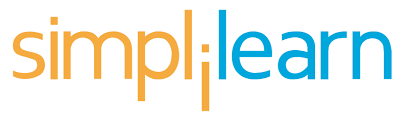 </a>|Very general tutorial including videos and an overview of top deep learning platforms|
|<a href="http://d2l.ai/"> 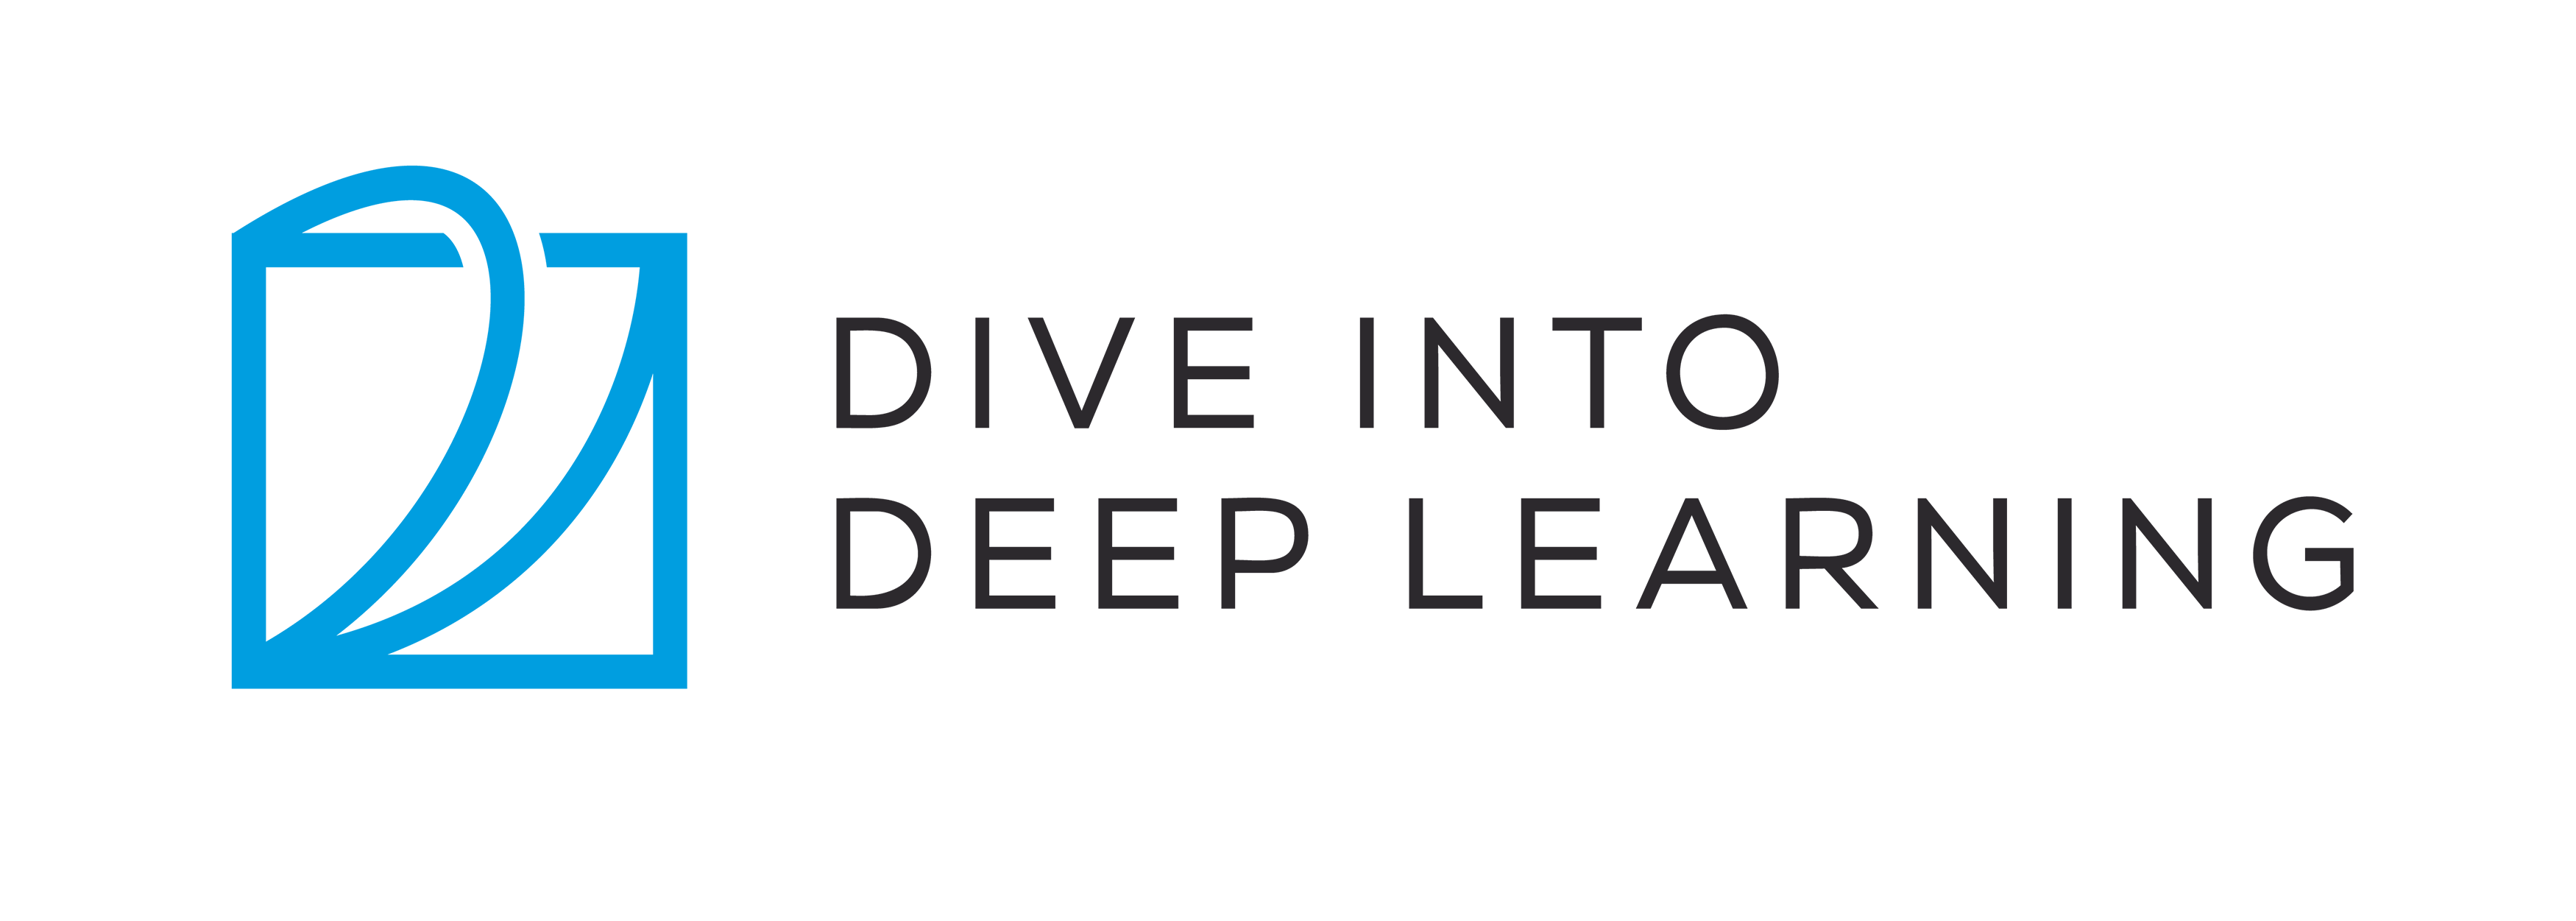 </a>|Very complete book with a lot of theory and examples for MxNET, PyTorch, and TensorFlow|
|<a href="https://pytorch.org/tutorials/"> 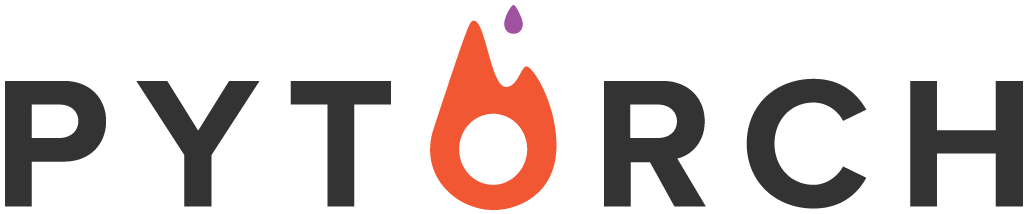 </a>|Official tutorials from the PyTorch project. Contains a 60 min overview, and a very practical *learning PyTorch with examples* tutorial|
|<a href="https://www.kaggle.com/kanncaa1/deep-learning-tutorial-for-beginners"> 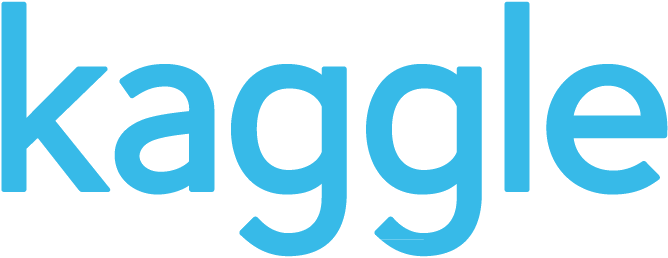 </a>|Kaggle tutorials covering an introduction to Neural Networks using Numpy, and a second one offering a PyTorch tutorial|

In addition to this, PyTorch MOOCs can be followed for free in main sites: edX, Coursera, Udacity

## <font color='teal'> 2. Datasets </font>

Along this notebook, we will run some experiments to solve classification problems using two image datasets, that we name "digits" and "DogCats"

### <font color='olive'>Digits: a sign language digits data set</font>

* Dataset is taken from <a href="https://www.kaggle.com/ardamavi/sign-language-digits-dataset"> Kaggle</a> and used in the above referred tutorial
* 2062 digits in sign language. $64 \times 64$ images
* Problem with 10 classes. One hot encoding for the label matrix
* Input data are images, we create also a flattened version

In [ ]:
# Load images and labels
digitsX = np.load('./data/Sign-language-digits-dataset/X.npy')
digitsY = np.load('./data/Sign-language-digits-dataset/Y.npy')

# Flatten images to get 1-dimensional inputs
K = digitsX.shape[0]
img_size = digitsX.shape[1]
digitsX_flatten = digitsX.reshape(K, img_size * img_size)

print('Size of Input Data Matrix:', digitsX.shape)
print('Size of Flattened Input Data Matrix:', digitsX_flatten.shape)
print('Size of label Data Matrix:', digitsY.shape)

# Show sample images
selected = [260, 1400]
plt.subplot(1, 2, 1), plt.imshow(digitsX[selected[0]].reshape(img_size, img_size)), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(digitsX[selected[1]].reshape(img_size, img_size)), plt.axis('off')
plt.show()
print('Labels corresponding to figures:', digitsY[selected, ])

### <font color='olive'> DogCats: a dataset of dogs and cat images </font>

* Dataset is taken from <a href="https://www.kaggle.com/c/dogs-vs-cats"> Kaggle</a>
* 25000 pictures of dogs and cats
* Binary problem
* Input data are images, we create also a flattened version
* Original images are RGB, and arbitrary size
* Preprocessed images are $64 \times 64$ and gray scale

In [ ]:
# Preprocessing of the original Dogs and Cats pictures
# Adapted from
# https://medium.com/@mrgarg.rajat/kaggle-dogs-vs-cats-challenge-complete-step-by-step-guide-part-1-a347194e55b1
# RGB channels are collapsed into GRAYSCALE, and images are resampled to 64x64.
# This code has been used to generate the adapted dataset used in this notebook, which is
# stored in ./data/DogsCats/ . You can uncomment it to re-generate the dataset, if needed.
"""
import os, cv2  # cv2 -- OpenCV

train_dir = './data/DogsCats/train/'
rows, cols = 64, 64
train_images = sorted([train_dir + i for i in os.listdir(train_dir)])

def read_image(file_path):
    image = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
    return cv2.resize(image, (rows, cols), interpolation=cv2.INTER_CUBIC)

def prep_data(images):
    m = len(images)
    X = np.ndarray((m, rows, cols), dtype=np.uint8)
    y = np.zeros((m,))
    print("X.shape is {}".format(X.shape))

    for i, image_file in enumerate(images):
        image = read_image(image_file)
        X[i, ] = np.squeeze(image.reshape((rows, cols)))
        if 'dog' in image_file.split('/')[-1].lower():
            y[i] = 1
        elif 'cat' in image_file.split('/')[-1].lower():
            y[i] = 0

        if i % 5000 == 0:
            print(f"Proceed {i} of {m}")

    return X, y

X_train, y_train = prep_data(train_images)
np.save('./data/DogsCats/X.npy', X_train)
np.save('./data/DogsCats/Y.npy', y_train)
"""
None

In [ ]:
# Load images and labels
DogsCatsX = np.load('./data/DogsCats/X.npy')
DogsCatsY = np.load('./data/DogsCats/Y.npy')

# Flatten images to get 1D inputs
K = DogsCatsX.shape[0]
img_size = DogsCatsX.shape[1]
DogsCatsX_flatten = DogsCatsX.reshape(K,img_size*img_size)

print('Size of Input Data Matrix:', DogsCatsX.shape)
print('Size of Flattened Input Data Matrix:', DogsCatsX_flatten.shape)
print('Size of label Data Matrix:', DogsCatsY.shape)

# Show sample images
selected = [260, 16000]
plt.subplot(1, 2, 1), plt.imshow(DogsCatsX[selected[0]].reshape(img_size, img_size)), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(DogsCatsX[selected[1]].reshape(img_size, img_size)), plt.axis('off')
plt.show()
print('Labels corresponding to figures:', DogsCatsY[selected,])

Now we define a function that, given the dataset name, prepares the data for binary or
multiclass classification. The data are split into two sets for training and validation,
and then normalized.

Note the order: **the scaler is fit on the training partition only**, and then applied to
the validation partition. Fitting it on the whole dataset before splitting would let
information from the validation data leak into the training pipeline. The effect is small
for a global image rescaling, but the habit is what matters.

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

def get_dataset(dataset_name, force_binary=False):
    """
    Loads the selected dataset, among two options: DogsCats or digits.

    If dataset_name == 'digits', you can take a dataset with two classes only,
    using force_binary == True
    """

    if dataset_name == 'DogsCats':
        X = DogsCatsX_flatten
        y = DogsCatsY
    elif dataset_name == 'digits':
        if force_binary:
            # Zeros and ones are one-hot encoded in columns 1 and 4
            X0 = digitsX_flatten[np.argmax(digitsY, axis=1) == 1, ]
            X1 = digitsX_flatten[np.argmax(digitsY, axis=1) == 4, ]
            X = np.vstack((X0, X1))
            y = np.zeros(X.shape[0])
            y[X0.shape[0]:] = 1
        else:
            X = digitsX_flatten
            y = digitsY
    else:
        raise ValueError(f"Unknown dataset: {dataset_name}")

    # Generate train and validation data, shuffle
    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=0.2, random_state=42, shuffle=True)

    # Normalization. For images, [-.5, .5] scaling is frequent.
    # The scaler is fit on the training data only, and then applied to both partitions.
    min_max_scaler = MinMaxScaler(feature_range=(-.5, .5))
    X_train = min_max_scaler.fit_transform(X_train)
    X_val = min_max_scaler.transform(X_val)

    return X_train, X_val, y_train, y_val

## <font color='teal'> 3. Introduction to Neural Networks </font>

In this section, we will implement neural networks from scratch using Numpy arrays (i.e., no PyTorch will be used in this section)

* No need to learn any new Python libraries
* But we need to deal with complexity of multilayer networks
* Low-level implementation will be useful to grasp the most important concepts concerning DNNs
    * Back-propagation
    * Activation functions
    * Loss functions
    * Optimization methods
    * Generalization
    * Special layers and configurations

### <font color='teal'> 3.1. A Single-Layer Neural Network for binary classification</font>

#### <font color='teal'> 3.1.1. Architecture </font>

One of the simplest neural network architectures for binary classification is shown in the figure

<center>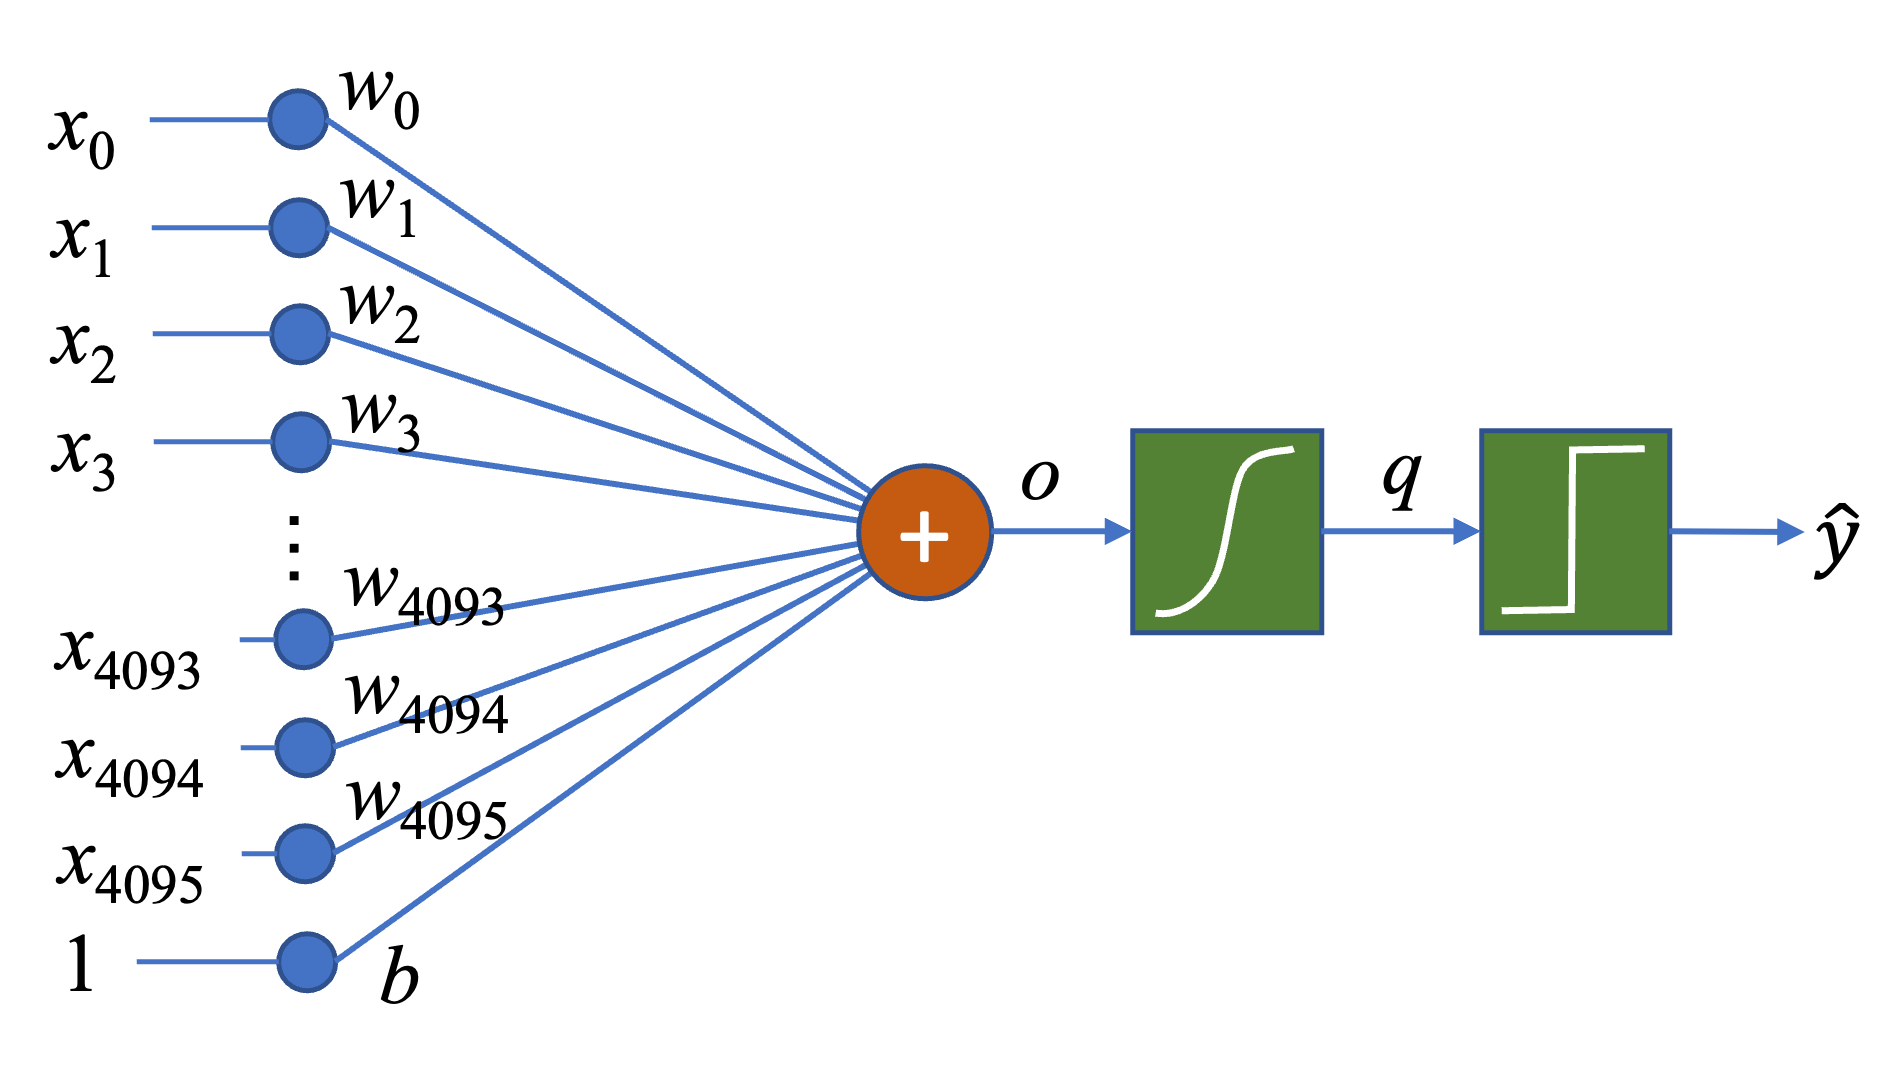</center>

The main components are:

 *  A **linear combination** of the input features is computed to produce the intermediate output
$$
o = {\bf w}^\intercal {\bf x} + b
$$

 * An **activation function**, which maps the linear combination to values in a bounded range, to produce the *soft* prediction
$$
q = g(o)
$$
A common choice for binary classification is the logistic function, which provides probabilistic predictions $q\in [0, 1]$,
$$
q = \text{logistic}(o) = \frac{1}{1 + \exp(-o)}.
$$
However, other activation functions are possible.

 * A **binary threshold**, transforming the *soft* prediction into a *hard* decision (the class prediction) in $\{0, 1\}$. Following the probabilistic interpretation of the soft prediction, a common choice is to apply a threshold $\frac12$, so that
$$
\hat{y} = \left[
    \begin{array}{ll}
    1, &  \text{if } q \ge \frac12   \\
    0, &  \text{if } q < \frac12
    \end{array} \right.
$$

We will define a ${\tt forward}$ method to implement the computation of the soft prediction, $q$. To do so, we define a method to implement the logistic function, too.

In [ ]:
# Define some useful functions
def logistic(t):
    """
    Computes the logistic function
    """
    return 1.0 / (1 + np.exp(-t))

def forward(w, b, x):
    """
    Computes the network output
    """
    return logistic(x @ w + b)

For binary classification, our goal is to fit the weights so that the hard predictions are correct. Therefore, a natural measure of the classification performance is the accuracy, defined as the average number of correct decisions.

In [ ]:
def accuracy(y, q):
    return np.mean(y == (q >= 0.5))

#### <font color='teal'> 3.1.2. Loss functions </font>

The accuracy is a good measure for the evaluation of the classifiers, but it is not useful to define the learning algorithm. This is because learning algorithms for neural networs are mostly based on gradient-based optimization techniques. The thresholding function is not differentiable at $\frac{1}{2}$ and its derivative is zero elsewhere. Therefore, the derivatives of the accuracy with respect to the weights are not useful to guide learning.

For this reason, we need a **loss function**, that is, a measure of discrepancy between the true class, $y$, and the soft prediction $q$,
$$
\ell(y, q)
$$
that could be used for training. A basic learning algorithm will try to minimize the **empirical risk**, defined as cumulative loss over the whole training set
$$
R({\bf w}, b) = \sum_{k=0}^{K-1} \ell(y_k, q_k)
$$

Many losses have been proposed for neural networks. Some examples are:
* **Square error**: $\ell_2(y, q) = (y-q)^2$
* **Absolute error**: $\ell_1(y, q) = |y - q|$
* **Cross entropy**: $\ell_\text{CE}(y, q) = - y \log(q) - (1-y) \log(1-q)$

For binary classification, cross entroy is the most common choice.

#### <font color='teal'> 3.1.3. Logistic Regression vs Single Layer NN</font>

Any neural network with probabilistic soft decisions defines a parametric probability model of the data. For the single-layer NN, the parametric model will be
$$
P(y=1|{\bf w}, b, {\bf x}) = g({\bf w}^\intercal {\bf x} + b)
$$

Therefore, we can train a neural network following a probabilistic approach. For instance, the negative log likelihood will be given by
\begin{align}
\text{NLL}({\bf w}, b) &= - \sum_{k=0}^{K-1} \log(P(y_k|{\bf w}, b, {\bf x}))    \\
    &= - \sum_{k=0}^{K-1} \left(y_k \log(P(1|{\bf w}, b, {\bf x})) + (1-y_k) \log( P(0|{\bf w}, b, {\bf x})) \right)  \\
    &= - \sum_{k=0}^{K-1} \left(y_k \log(q_k) + (1-y_k) \log(1-q_k) \right)   \\
    &= \sum_{k=0}^{K-1} \ell_\text{CE}(y_k, q_k)
\end{align}
which shows that the empirical risk of the cross entropy is the NLL and, thus, optimizing the cross entropy provides ML estimates of the weights.

This also shows that a single-layer NN with logistic activation and cross-entropy loss is completely equivalent to a logistic regression model adjusted with ML.

#### <font color='teal'> 3.1.4. Training </font>

In order to find parameters $\bf w$ and $b$, we will minimize the NLL via gradient descent optimization.

The gradient computation can be simplified using the **<font color='navy'>chain rule</font>**

\begin{align}
\frac{\partial \text{NLL}}{\partial {\bf w}}
    & = \frac{\partial \text{NLL}}{\partial q} \cdot \frac{\partial q}{\partial o}
                                               \cdot \frac{\partial o}{\partial {\bf w}} \\
    & = \sum_{k=0}^{K-1} \left[\frac{1-y_k}{1-q_k} - \frac{y_k}{q_k}\right]q_k (1-q_k) {\bf x}_k \\
    & = \sum_{k=0}^{K-1} (q_k - y_k) {\bf x}_k \\
\frac{\partial \text{NLL}}{\partial b} & = \sum_{k=0}^{K-1} (q_k - y_k)
\end{align}

Therefore, the gradient descent rules are
$${\bf w}_{n+1} = {\bf w}_n + \rho_n \sum_{k=0}^{K-1} (y_k - q_{k,n}){\bf x}_k$$
$$b_{n+1} = b_n + \rho_n \sum_{k=0}^{K-1} (y_k - q_{k,n}),$$

where $q_{k,n}$ is the probabilistic prediction for sample $k$. It depends on $n$ because it depends on the weights, which change at each iteration.

In [ ]:
def backward(y, q, x):
    """
    Computes the gradient of the loss function with respect to the network parameters.
    """
    w_grad = x.T @ (q - y) / len(y)
    b_grad = np.mean(q - y)
    return w_grad, b_grad

def loss(y, q, eps=1e-12):
    # eps avoids log(0) when the network becomes very confident
    q = np.clip(q, eps, 1 - eps)
    return - (y @ np.log(q) + (1 - y) @ np.log(1 - q)) / len(y)

#### <font color='teal'> 3.1.5. Testing the single layer NN </font>

Now, we will test the behavior of the single-layer NN with the given datasets

In [ ]:
# Load normalized data
X_train, X_val, y_train, y_val = get_dataset('digits', force_binary=True)

# Neural Network Training
epochs = 400
rho = .05    # Use this setting for Sign Digits Dataset

# Parameter initialization
w = .1 * rng.standard_normal(X_train.shape[1])
b = .1 * rng.standard_normal(1)

loss_train = np.zeros(epochs)
loss_val = np.zeros(epochs)
acc_train = np.zeros(epochs)
acc_val = np.zeros(epochs)

for epoch in np.arange(epochs):
    print(f"-- Epoch {epoch + 1} out of {epochs}    \r", end="")
    q_train = forward(w, b, X_train)
    q_val = forward(w, b, X_val)
    w_grad, b_grad = backward(y_train, q_train, X_train)
    w = w - rho * w_grad
    b = b - rho * b_grad

    loss_train[epoch] = loss(y_train, q_train)
    loss_val[epoch] = loss(y_val, q_val)
    acc_train[epoch] = accuracy(y_train, q_train)
    acc_val[epoch] = accuracy(y_val, q_val)

In [ ]:
plt.figure(figsize=(10,3))
plt.subplot(1, 2, 1), plt.plot(loss_train, 'b'), plt.plot(loss_val, 'r'), plt.legend(['train', 'val']),
plt.title('Cross-entropy loss')
plt.subplot(1, 2, 2), plt.plot(acc_train, 'b'), plt.plot(acc_val, 'r'), plt.legend(['train', 'val']),
plt.title('Accuracy')
plt.show()

#### <font color='olive'>Exercise 1 </font>

Study the behavior of the algorithm changing the number of epochs and the learning rate

In [ ]:
# <Write your code here>

#### <font color='olive'>Exercise 2 </font>

Repeat the analysis for the other dataset, trying to obtain as large an accuracy value as possible. What do you believe are the reasons for the very different performance for both datasets?

In [ ]:
# <Write your code here>

Linear logistic regression allowed us to review a few concepts that are key for Neural Networks:

* Network topology (In this case, a linear network with one layer)
* Activation functions
* Parametric approach ($\bf w$/$b$)
* Parameter initialization
* Obtaining the network prediction using *forward* computation
* Loss function
* Parameter gradient calculus using *backward* computation
* Optimization method for parameters update (here, GD)

### <font color='teal'> 3.2. Single-Layer Neural Networks for Multiclass Classification </font>

#### <font color='teal'> 3.2.1. Multiclass problems and one-hot encoding </font>

The single-layer NN can be easily extended to problems with $M \ge 2$ classes, $0, 1, \ldots, M-1$.

To do so, we will represent classes using one-hot encoding, that is, $M$-dimensional vectors with zero componentes unless for a value 1 in the position indicated by the class.

For instance, classes in $\{0, 1, 2, 3\}$ will be represented by vectors
$$
\begin{pmatrix} 1 \\ 0 \\ 0 \\ 0 \end{pmatrix} \, \,
\begin{pmatrix} 0 \\ 1 \\ 0 \\ 0 \end{pmatrix}, \, \,
\begin{pmatrix} 0 \\ 0 \\ 1 \\ 0 \end{pmatrix} \text{ and }
\begin{pmatrix} 0 \\ 0 \\ 0 \\ 1 \end{pmatrix},
$$
respectively.

Thus, both the true-class, ${\bf y}$, and the prediction, $\hat{\bf y}$, will be one-hot $M$-dimensional vectors .

#### <font color='teal'> 3.2.2. Architecture </font>

A natural extension of the single layer NN to multiple classes is shown in the figure

<center>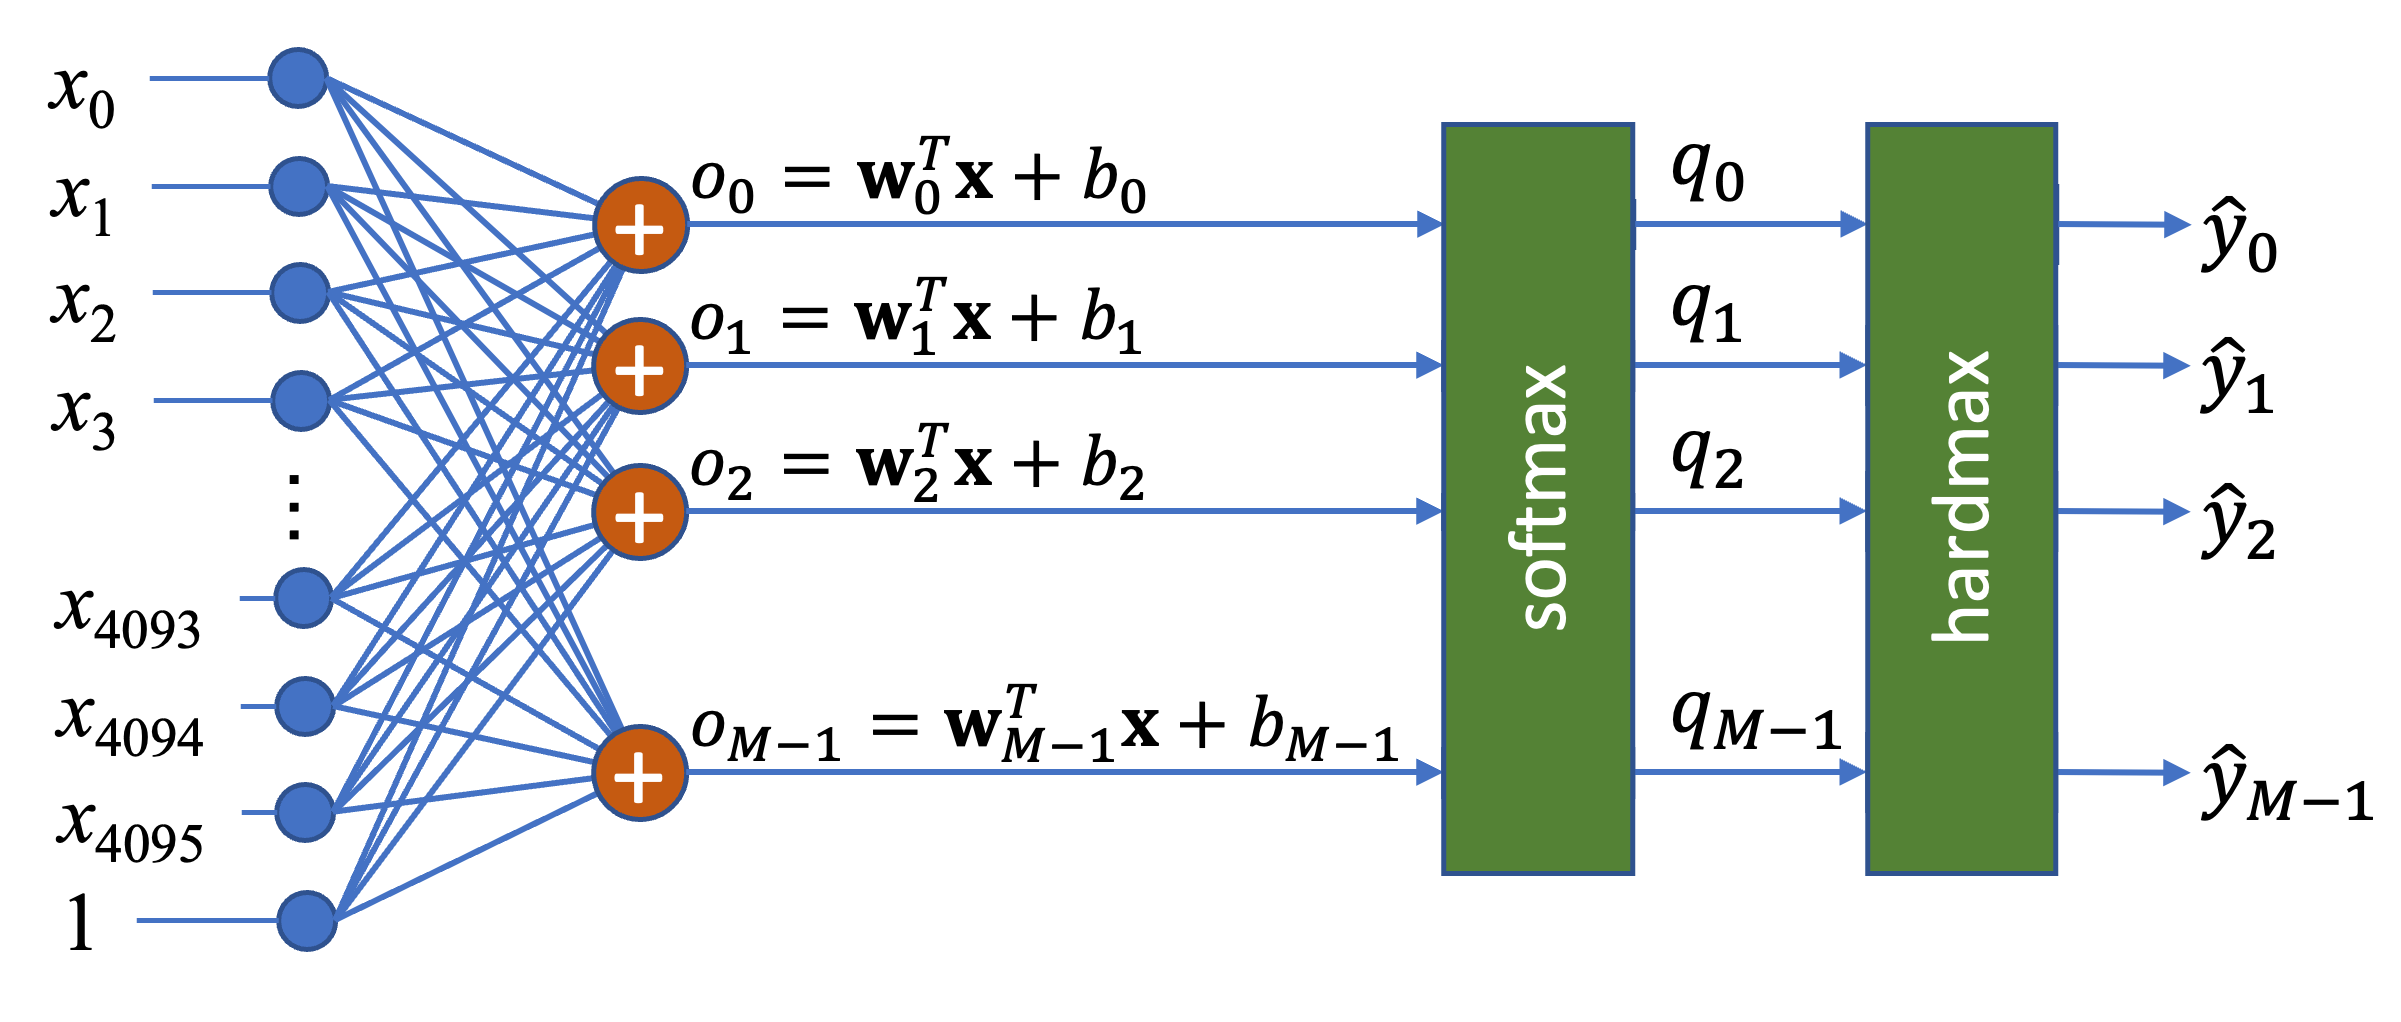</center>

The components of the multiclass model are multidimensional extensions of those of the single-layer NN for the binary classification problem:

 * A **linear combination** is computed per each class. Note that, defining the matrix ${\bf W}=({\bf w}_0| {\bf w}_1 | \cdots | {\bf w}_{M-1})^\intercal$, we can write
$$
{\bf o} = {\bf W}{\bf x} + {\bf b}
$$

 * **Activation function**. The **softmax** function is the most common choice. It is a multidimensional generalization of the logistic function (invented in 1959 by the social scientist R. Duncan Luce) and defined as
\begin{align}
q_i = \frac{\exp(o_i)}{\sum_{j=0}^{M-1} \exp(o_j)},
\end{align}
and it provides probabilistic soft predictions because
$$0 \le q_i \le 1$$
$$\sum_{j=0}^{M-1} q_j =1$$
The derivatives of the softmax components, that will be required for training, are given by
\begin{align}
\frac{\partial q_i}{\partial o_i} &= q_i (1 - q_i) \\
\frac{\partial q_i}{\partial o_j} &= - q_i q_j,  \qquad  j \neq i
\end{align}

* **Class prediction**: the final transformation maps the probabilistic predictions into a class prediction in one-hot form. Following the probabilistic interpretation of the soft prediction, we can use the **hardmax** function, which outputs a zero vector with a unit value in the ouput corresponding to the highest probabilistic input, that is,
\begin{align*}
\hat{y}_i =
\left[ \begin{array}{ll}
        1, & {\rm if}\,\,  q_i = \max_j q_j  \\
        0, & {\rm otherwise}
\end{array} \right.
\end{align*}
The classifier is still linear, in the sense that
$$\text{hardmax}({\bf q}) = \text{hardmax}({\bf o}) = \text{hardmax}({\bf W} {\bf x} + {\bf b})$$

#### <font color='teal'> 3.2.3. Loss function </font>

The losses defined for the binary case can be easily extended to the multiclass setting:

The multi-class version of the cross entropy is defined as
* **Square error**:    $\,\, \ell_2({\bf y}, {\bf q}) = \|{\bf y} - {\bf q}\|^2$
* **Absolute error**:  $\,\, \ell_1({\bf y}, {\bf q}) = \|{\bf y} - {\bf q}\|_1$
* **Cross entropy**:   $\,\, \ell_\text{CE}({\bf y}, {\bf q}) = - \sum_{j=0}^{M-1} y_j \log(q_j)$

We will implement the cross entropy. For evaluation purposes, the accuracy will be used

In [ ]:
def accuracy(y, q):
    return np.mean(np.argmax(y, axis=1) == np.argmax(q, axis=1))

def loss(y, q, eps=1e-12):
    # Average cross entropy per sample, so that its value is comparable with the one
    # obtained for the binary problem (and with the PyTorch losses of the next notebook)
    q = np.clip(q, eps, None)
    return - np.sum(y * np.log(q)) / len(y)

#### <font color='teal'> 3.2.4. Probabilistic model </font>

As in the binary case, any neural network architecture with a probabilistic activation function defines a parametric probability model. For the architecture in the figure, such model is given by
$$
P(y_i=1|{\bf x}, {\bf W}, {\bf b}) = q_i
$$
$$
{\bf q} = \text{softmax}({\bf W}{\bf x} + {\bf b})
$$

Consequently, the negative log-likelihood is identical to the empirical risk defined by the cross entropy, that is
$$
\text{NLL}({\bf W}, {\bf b}) = \sum_{k=0}^{K-1} \ell_\text{CE}({\bf y}_k, {\bf q}_k)
$$

We will define a method to compute the softmax activation, and a ${\tt forward}$ method to compute the soft prediction from the inputs

In [ ]:
# Define some useful functions
def softmax(t):
    """Compute softmax values for each set of scores in t.

    The maximum of each row is subtracted before taking the exponential. This does not
    change the result (the constant cancels out in the quotient) but it avoids the
    overflow of np.exp() for large scores.
    """
    e_t = np.exp(t - t.max(axis=1, keepdims=True))
    return e_t / e_t.sum(axis=1, keepdims=True)

def forward(w, b, x):
    # Compute the soft prediction of the network
    return softmax(x @ w.T + b.T)

#### <font color='teal'> 3.2.4. Training </font>

The Gradient Descent learning rules are given by
$${\bf W}_{n+1} = {\bf W}_n - \rho_n \sum_{k=0}^{K-1} \frac{\partial l({\bf y}_k,{{\bf q}_k})}{\partial {\bf W}}$$
$${\bf b}_{n+1} = {\bf b}_n - \rho_n \sum_{k=0}^{K-1} \frac{\partial l({\bf y}_k,{{\bf q}_k})}{\partial {\bf b}}$$

Applying the chain rule, and using the derivatives of the softmax function, the derivatives can be computed as follows:

\begin{align}
\frac{\partial l({\bf y}, {\bf q})}{\partial {\bf W}}
    &= \frac{\partial l({\bf y}, {\bf q})}{\partial {\bf o}}
                 \cdot \frac{\partial {\bf o}}{\partial {\bf W}} \\
    &= \sum_{i=0}^{M-1}
           \frac{\partial l({\bf y}, {\bf q})}{\partial o_i}
               \cdot \frac{\partial o_i}{\partial {\bf W}} \\
    &= \frac{\partial l({\bf y}, {\bf q})}{\partial {\bf o}}
           \cdot {\bf x}^\intercal \\
    &= \frac{\partial {\bf q}}{\partial {\bf o}}
           \cdot \frac{\partial l({\bf y}, {\bf q})}{\partial {\bf q}}
           \cdot {\bf x}^\intercal \\
    & = \left[\begin{array}{ccccc}
                  q_1 (1 - q_1) & - q_1 q_2      & \dots  & - q_1 q_{M-1} \\
                  - q_2 q_1      & q_2 (1 - q_2) & \dots  & - q_2 q_{M-1} \\
                  \vdots                  & \vdots                  & \ddots & \vdots                 \\
                  - q_{M-1} q_1 & -q_{M-1} q_2  & \dots  & q_{M-1} (1-q_{M-1})  
              \end{array}\right]
        \left[\begin{array}{c} -y_1/q_1 \\ -y_2/q_2 \\ \vdots \\ - y_{M-1}/q_{M-1} \end{array}\right]
        {\bf x}^\intercal \\
    & = ({\bf q} - {\bf y}){\bf x}^\intercal \\
\\
\frac{\partial l({\bf y},{{\bf q}})}{\partial {\bf b}}
    & = {\bf q} - {\bf y}
\end{align}

Thus, the gradient descent learning rules are
$${\bf W}_{n+1} = {\bf W}_n + \rho_n \sum_{k=0}^{K-1} ({\bf y}_k - {\bf q}_{k,n}) \cdot {\bf x}_k^\intercal$$
$${\bf b}_{n+1} = {\bf b}_n + \rho_n \sum_{k=0}^{K-1} ({\bf y}_k - {\bf q}_{k,n}) $$
where ${\bf q}_{k,n}$ is the soft prediction for sample $k$. It depends on $n$ because the soft prediction depends on the weights, which change at each iteration.

In [ ]:
def backward(y, q, x):
    # Calcula los gradientes
    W_grad = (q - y).T @ x / len(y)
    b_grad = (q - y).T.mean(axis=1, keepdims=True)
    return W_grad, b_grad

#### <font color='teal'> 3.2.5. Testing the multi-class single-layer NN </font>

Now, we will test the behavior of the multiclass NN with the `digits` dataset.

In [ ]:
X_train, X_val, y_train, y_val = get_dataset('digits')
print('Training data:', X_train.shape, ' Validation data:', X_val.shape)

In [ ]:
# Neural Network Training

epochs = 300
rho = .1

# Parameter initialization
W = .1 * rng.standard_normal((y_train.shape[1], X_train.shape[1]))
b = .1 * rng.standard_normal((y_train.shape[1], 1))

loss_train = np.zeros(epochs)
loss_val = np.zeros(epochs)
acc_train = np.zeros(epochs)
acc_val = np.zeros(epochs)

for epoch in np.arange(epochs):
    print(f"Epoch {epoch + 1} out of {epochs}   \r", end="")
    q_train = forward(W, b, X_train)
    q_val = forward(W, b, X_val)
    W_grad, b_grad = backward(y_train, q_train, X_train)
    W = W - rho * W_grad
    b = b - rho * b_grad

    loss_train[epoch] = loss(y_train, q_train)
    loss_val[epoch] = loss(y_val, q_val)
    acc_train[epoch] = accuracy(y_train, q_train)
    acc_val[epoch] = accuracy(y_val, q_val)

In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1, 2, 1), plt.plot(loss_train, 'b'), plt.plot(loss_val, 'r'),
plt.legend(['train', 'val']), plt.title('Cross-entropy loss')
plt.subplot(1, 2, 2), plt.plot(acc_train, 'b'), plt.plot(acc_val, 'r'),
plt.legend(['train', 'val']), plt.title('Accuracy')
plt.show()

#### <font color='olive'>Exercise 3</font>

Study the behavior of the algorithm changing the number of epochs and the learning rate

In [ ]:
# Write your code here

#### <font color='olive'>Exercise 4</font>

Obtain the confusion matrix, and study which classes are more difficult to classify

In [ ]:
# Write your code here

#### <font color='olive'>Exercise 5</font>

Think about the differences between using this 10-class network, vs training 10 binary classifiers, one for each class

In [ ]:
# Write your response here

As in linear logistic regression note that we covered the following aspects of neural network design, implementation, and training:

* Network topology (In this case, a linear network with one layer and $M$ ouptuts)
* Activation functions (softmax activation)
* Initialization of parameters ($\bf W$, $\bf b$)
* Obtaining the network prediction using *forward* computation
* Loss function
* Gradient calculus using *backward* computation
* Optimization method for parameters update (here, GD)

### <font color='teal'> 3.3. Multi Layer Networks (Deep Networks) </font>

Previous networks are constrained in the sense that they can only implement linear classifiers: the boundary decision of a binary single-layer NN is linear (an hyperplane) and the boundary sepearating each pair of classes in a multi-class single-layer NN is also linear.

As in logistic regression, we can easily apply the single-layer NN to non-linear classification problems by using fixed non-linear transformations of the inputs: ${\bf z} = {\bf{f}}({\bf x})$, as the inputs to the linear layer. However, a fixed non-linear transformation limits the adaptability of the network to different datasets.

An interesting alternative is to parametrize the transformation using one or more non-linear layers of neurons. This is the central idea of the **multi-layer perceptron** (MLP).

<center>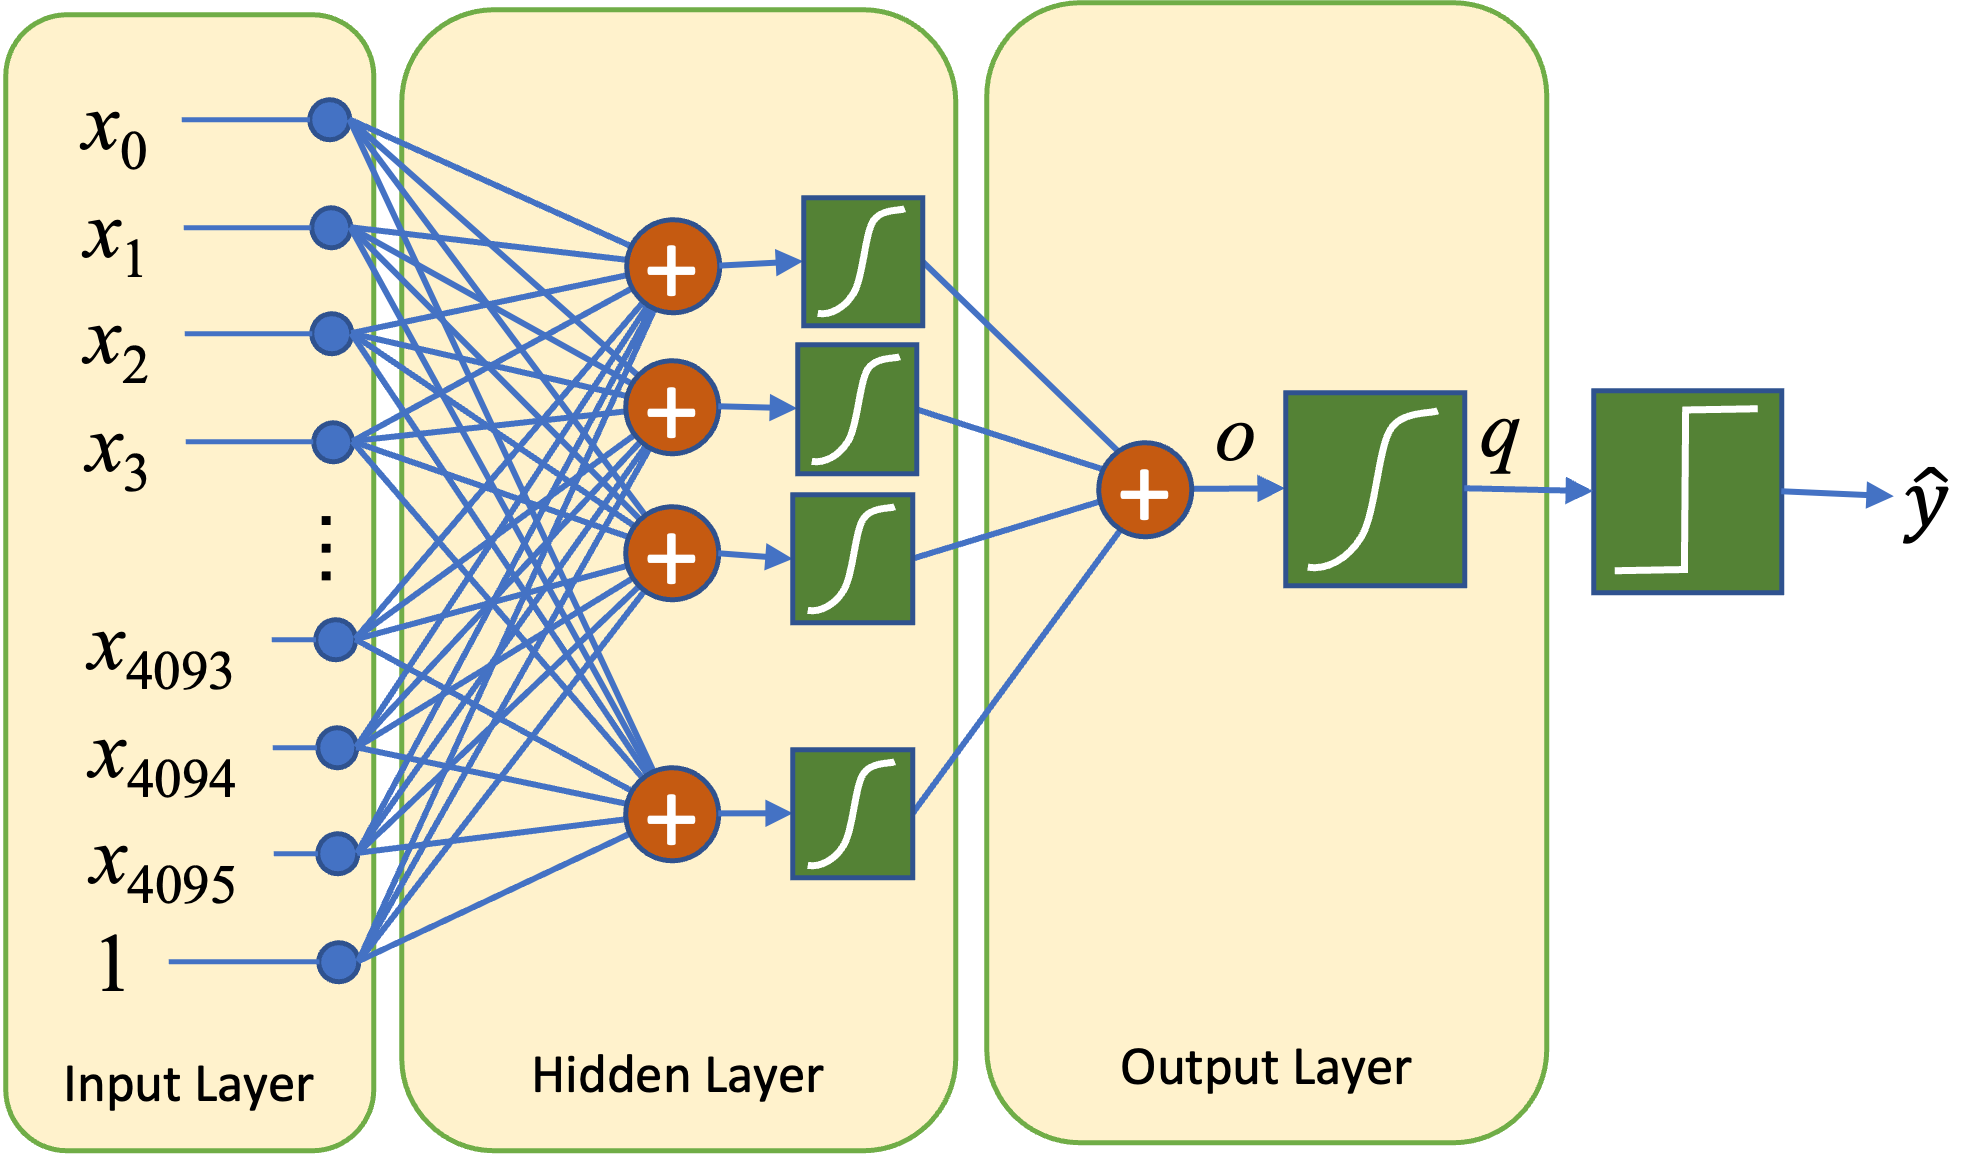</center>

* When counting layers, we normally ignore the input layer, since there is no computation involved
* Intermediate layers are normally referred to as "**hidden layers**"
* **Non-linear activations** result in an overall non-linear classifier
* We can still use **gradient descent optimization** as long as the derivatives of the loss function with respect to all parameters exist.
* This is already **deep learning**. We can have two layers or more, each with different numbers of neurons. But as long as derivatives with respect to parameters can be calculated, the network can be optimized
* **Structural optimization**: Finding an appropriate number of layers for a particular problem, as well as the number of neurons per layer, requires exploration
* The more data we have for training the network, the more parameters we can afford, making feasible the use of more complex topologies

#### <font color='teal'> 3.3.1. Example: a 2-layer network for binary classification</font>

##### <font color='teal'> Network topology

The forward computation graph, shown in the figure, illustrates the computation steps that produce the network prediction and the loss computation
<center>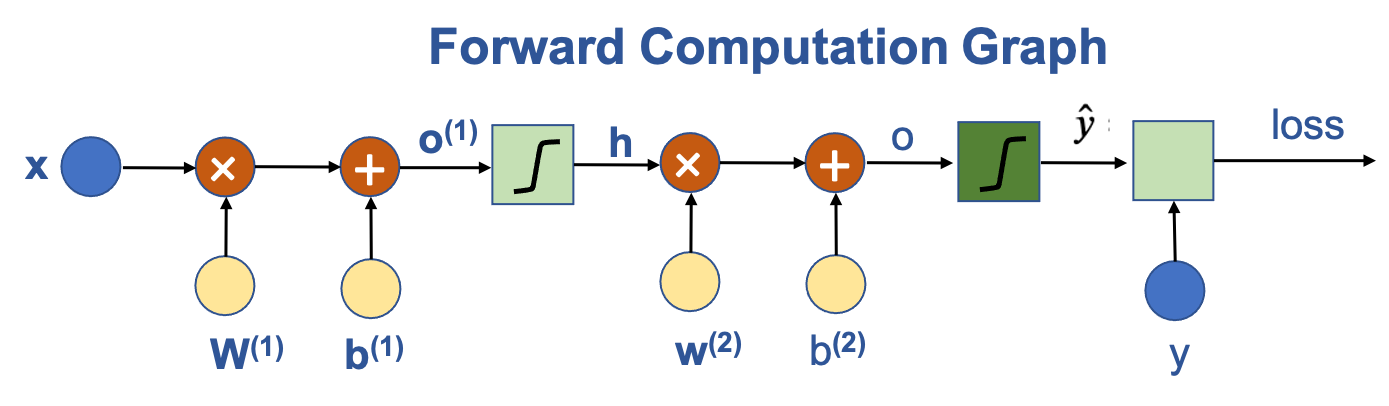</center>

  * **Hidden layer**: one hidden layer with $n_h$ neurons with hyperbolic tangent
    activation. The hyperbolic tangent is a rescaled version of the logistic function
    producing outputs in the interval $[-1, 1]$,
    $$\tanh(o) = 2\,\text{logistic}(2 o) - 1.$$
    It does not produce probabilistic outputs, but they are not needed at intermediate
    layers.

  * **Output layer**: a single neuron with logistic activation function.
  * **Loss function**: Cross-entropy

The network equations are, thus:

$${\bf h} = \text{tanh}({\bf o}^{(1)})= \text{tanh}\left({\bf W}^{(1)} {\bf x} + {\bf b}^{(1)}\right)$$
$$q = \text{logistic}(o) = \text{logistic}\left({{\bf w}^{(2)}}^\top {\bf h} + b^{(2)}\right)$$

(where the hyperbolic tangent of a vector is computed component-wise). They are
implemented in the forward method, below.

In [ ]:
# Define some useful functions
def logistic(t):
    return 1.0 / (1 + np.exp(-t))

def forward(W1, b1, w2, b2, x):
    # Compute the network output
    h = np.tanh(x @ W1.T + b1)
    q = logistic(h @ w2 + b2)
    # Return also the hidden units value, needed for the backward step
    return h, q

##### <font color='teal'> Training

We will train the neural network by applying the gradient descent learning rule to the minimization of the NLL (i.e. the cumulative cross entropy).

  To do so, we need to compute the derivatives of the loss with respect to every network parameter. We will do it by applying extensively the chain rule:

  * **Output layer** weights: the derivatives are the same that we have computed for the
    single-layer NN, since the dependency of the loss on the output layer weights is the
    same (we just need to use ${\bf h}$ instead of ${\bf x}$):

  $${\bf w}_{n+1}^{(2)} = {\bf w}_n^{(2)} + \rho_n \sum_{k=0}^{K-1} (y_k - q_{k,n}){\bf h}_{k,n}$$
  $$b_{n+1}^{(2)} = b_n^{(2)} + \rho_n \sum_{k=0}^{K-1} (y_k - q_{k,n})$$

  * **Hidden layer** weights: we need to use the chain rule (we ignore dimensions and
    rearrange at the end). The only new ingredient is the derivative of the hyperbolic
    tangent, which can be written in terms of its own output:
    $$\frac{\partial h_i}{\partial o^{(1)}_i} = 1 - \tanh^2(o^{(1)}_i) = 1 - h_i^2$$

\begin{align}
\\
\frac{\partial \ell_\text{CE}(y, q)}{\partial {\bf W}^{(1)}}
    & = \frac{\partial \ell_\text{CE}(y, q)}{\partial o}
            \cdot \frac{\partial o}{\partial {\bf h}}
            \cdot \frac{\partial {\bf h}}{\partial {\bf o}^{(1)}}
            \cdot \frac{\partial {\bf o}^{(1)}}{\partial {\bf W}^{(1)}} \\
    & = (q - y) \left[{\bf w}^{(2)} \odot ({\bf 1}-{\bf h}^2)\right] {\bf x}^{\top}
\end{align}
   
 where $\odot$ denotes component-wise multiplication and the square of ${\bf h}$ is
    also computed component-wise. (Note, also, that
    $\frac{\partial {\bf o}^{(1)}}{\partial {\bf W}^{(1)}}$ is actually a three
    dimensional matrix (i.e. a *tensor*). To apply the chain rule properly, the
    multiplications in the above equation must represent the adequate tensor products)

\begin{align}
\\
\frac{\partial \ell_\text{CE}(y, q)}{\partial {\bf b}^{(1)}}
    & = (q - y) \left[{\bf w}^{(2)} \odot ({\bf 1}-{\bf h}^2)\right]
\end{align}

* GD update rules become
$${\bf W}_{n+1}^{(1)} = {\bf W}_n^{(1)} + \rho_n \sum_{k=0}^{K-1} (y_k - q_{k,n})\left[{\bf w}^{(2)} \odot ({\bf 1}-{\bf h}_{k,n}^2)\right] {\bf x}_k^{\top}$$
$${\bf b}_{n+1}^{(1)} = {\bf b}_n^{(1)} + \rho_n \sum_{k=0}^{K-1} (y_k - q_{k,n})\left[{\bf w}^{(2)} \odot ({\bf 1}-{\bf h}_{k,n}^2)\right]$$

In [ ]:
def backward(y, q, h, x, w2):
    # delta of the output layer
    delta2 = q - y
    w2_grad = h.T @ delta2 / len(y)
    b2_grad = np.mean(delta2)

    # delta of the hidden layer: back-propagate delta2 through w2 and through the
    # derivative of the tanh, which is (1 - h**2)
    delta1 = w2[np.newaxis, ] * (1 - h**2) * delta2[:, np.newaxis]
    W1_grad = delta1.T @ x / len(y)
    b1_grad = delta1.sum(axis=0) / len(y)

    return w2_grad, b2_grad, W1_grad, b1_grad

def accuracy(y, q):
    return np.mean(y == (q >= 0.5))

def loss(y, q, eps=1e-12):
    q = np.clip(q, eps, 1 - eps)
    return - np.sum(y * np.log(q) + (1 - y) * np.log(1 - q)) / len(y)

#### <font color='olive'>Checking the gradients</font>

Hand-derived gradients are a classical source of silent errors: a wrong gradient often
still *trains* (the loss goes down) as long as the sign is right, so the bug does not
announce itself. The standard defense is a **numerical gradient check**: perturb one
parameter by a small $\epsilon$ and compare the finite difference of the loss with the
analytical derivative.

In [ ]:
def gradient_check(n_h=4, D=6, K=30, eps=1e-6):
    """Compares the analytical gradient of W1 with a numerical approximation."""
    x = rng.standard_normal((K, D))
    y = (rng.random(K) > .5).astype(float)
    W1 = .5 * rng.standard_normal((n_h, D))
    b1 = .5 * rng.standard_normal(n_h)
    w2 = .5 * rng.standard_normal(n_h)
    b2 = .5 * rng.standard_normal(1)

    h, q = forward(W1, b1, w2, b2, x)
    _, _, W1_grad, _ = backward(y, q, h, x, w2)

    W1_num = np.zeros_like(W1)
    for i in range(W1.shape[0]):
        for j in range(W1.shape[1]):
            Wp, Wm = W1.copy(), W1.copy()
            Wp[i, j] += eps
            Wm[i, j] -= eps
            lp = loss(y, forward(Wp, b1, w2, b2, x)[1])
            lm = loss(y, forward(Wm, b1, w2, b2, x)[1])
            W1_num[i, j] = (lp - lm) / (2 * eps)

    rel = np.linalg.norm(W1_grad - W1_num) / (np.linalg.norm(W1_grad) + np.linalg.norm(W1_num))
    print(f"Relative error between analytical and numerical gradient: {rel:.2e}")
    print("(it should be of the order of 1e-9 or smaller)")

gradient_check()

#### <font color='teal'> 3.3.2. The back-propagation algorithm </font>

The process that we have followed to compute the loss derivatives with respect to the weights can be extended to networks with an arbitrary number of layers.

Note that derivatives are computed backwards: from the last layer to the first hidden layer, so that we can use intermediate computations at a some layer to compute derivatives at layers that are further back.

For this reason, the gradient descent method is called the **back-propagation** algorithm.

#### <font color='teal'> 3.3.3. Testing the 2-layer network</font>

Now we are ready to evaluate the two layer network

In [ ]:
def evaluate_model(X_train, X_val, y_train, y_val, n_h=5, epochs=1000, rho=.005):

    W1 = .01 * rng.standard_normal((n_h, X_train.shape[1]))
    b1 = .01 * rng.standard_normal(n_h)
    w2 = .01 * rng.standard_normal(n_h)
    b2 = .01 * rng.standard_normal(1)

    loss_train = np.zeros(epochs)
    loss_val = np.zeros(epochs)
    acc_train = np.zeros(epochs)
    acc_val = np.zeros(epochs)

    for epoch in np.arange(epochs):
        print(f'Current epoch: {epoch + 1}  \r', end="")

        h, q_train = forward(W1, b1, w2, b2, X_train)
        _, q_val = forward(W1, b1, w2, b2, X_val)
        w2_grad, b2_grad, W1_grad, b1_grad = backward(y_train, q_train, h, X_train, w2)

        W1 = W1 - rho * W1_grad
        b1 = b1 - rho * b1_grad
        w2 = w2 - rho * w2_grad
        b2 = b2 - rho * b2_grad

        loss_train[epoch] = loss(y_train, q_train)
        loss_val[epoch] = loss(y_val, q_val)
        acc_train[epoch] = accuracy(y_train, q_train)
        acc_val[epoch] = accuracy(y_val, q_val)

    return loss_train, loss_val, acc_train, acc_val

Note that a **single learning rate** is used for both layers. The previous version of this
notebook needed a smaller step for the hidden layer, which was a symptom of the incorrect
hidden-layer gradient, not a property of the problem.

##### <font color='olive'>Results in Dogs vs Cats dataset</font>

In [ ]:
dataset = 'DogsCats'

X_train, X_val, y_train, y_val = get_dataset(dataset)
loss_train, loss_val, acc_train, acc_val = evaluate_model(
    X_train, X_val, y_train, y_val, n_h=5, epochs=500, rho=0.5)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1), plt.plot(loss_train, 'b'), plt.plot(loss_val, 'r'),
plt.legend(['train', 'val']), plt.title('Cross-entropy loss')
plt.subplot(1, 2, 2), plt.plot(acc_train, 'b'), plt.plot(acc_val, 'r'),
plt.legend(['train', 'val']), plt.title('Accuracy')
plt.show()
print('Final validation accuracy:', acc_val[-1])

##### <font color='olive'>Results in Binary Sign Digits Dataset</font>

In [ ]:
dataset = 'digits'
X_train, X_val, y_train, y_val = get_dataset(dataset, force_binary=True)
loss_train, loss_val, acc_train, acc_val = evaluate_model(
    X_train, X_val, y_train, y_val, n_h=5, epochs=2000, rho=0.5)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1), plt.plot(loss_train, 'b'), plt.plot(loss_val, 'r'),
plt.legend(['train', 'val']), plt.title('Cross-entropy loss')
plt.subplot(1, 2, 2), plt.plot(acc_train, 'b'), plt.plot(acc_val, 'r'),
plt.legend(['train', 'val']), plt.title('Accuracy')
plt.show()
print('Final validation accuracy:', acc_val[-1])

#### <font color='olive'>Exercise 6</font>

Train the network using other settings for:

* The number of epochs
* The learning step
* The number of neurons in the hidden layer

Some combinations will still **diverge**: with a large learning rate the weights grow,
the hidden units saturate at $\pm 1$, and the factor $(1 - h^2)$ of the gradient goes to
zero. **Optimized libraries rely on better initializations and on adaptive optimizers to
make training robust**; we will see them in the next notebook.

In [ ]:
# Write your solution here

#### <font color='olive'>Exercise 7</font>

Try to solve both problems using the <a href="https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html">scikit-learn implementation of the MLP</a>

* You can also explore other activation functions
* You can also explore other solvers to speed up convergence
* You can also adjust the size of minibatches
* Take a look at the *early_stopping* parameter

In [ ]:
# Write your solution here

### <font color='teal'> 3.4. Activation Functions</font>

The MLP with two layers that we have used as an example contains sigmoid-type activation functions (logistic or hyperbolic tangent), which produce bounded outputs.

A major inconvenient of these kind of activations is that their derivatives vanish for large values of the input. As a consequence, learning can get stucked in *flat* regions of the parameter space.

Activation functions must be non-linear (otherwise, all network layers could be colapsed into a single one), but they do not need to be neither probabilistic nor bounded (with the possible exception of the final layer).

For this reason, many other activation functions have been proposed. Some examples are

  * **ReLU** (Rectified Linear Unit):
    * ${\rm ReLU}(t) = \max(0, t)$.
    * It is a one-side linear function. Its derivative is the step function.
  * **PReLU** (Parametric Rectified Linear Unit):
    * ${\rm PReLU} = \max(\alpha t, t)$.
    * A modification of the ReLU that replaces the constant term 0 by a linear term with an adjustable parameter, that avoids zero derivatives. For $\alpha=0.01$, it is named **Leaky ReLU**.
  * **Softplus**:
    * ${\rm softplus}(t) = \log(1 + \exp(t))$.
    * Its derivative is the logistic function. It is a "soft" version of the ReLU: for large $|t|$, ${\rm softplus}(t) \approx {\rm ReLU}(t)$

(you can refer to the <a href="https://pytorch.org/docs/stable/nn.html#non-linear-activations-weighted-sum-nonlinearity">pytorch documentation </a> or the <a href="https://en.wikipedia.org/wiki/Activation_function"> Wikipedia</a> to see many other examples)

In [ ]:
x_array = np.linspace(-6, 6, 100)
relu = np.clip(x_array, 0, a_max=None)
softplus = np.log(1 + np.exp(x_array))
leaky_relu = np.clip(x_array, 0.1 * x_array, a_max=None)

fig, axs = plt.subplots(1, 3)
fig.set_figwidth(15)
axs[0].plot(x_array, relu)
axs[1].plot(x_array, leaky_relu)
axs[2].plot(x_array, softplus)
for ax in axs:
    ax.grid()
axs[0].set_title('ReLU activation function')
axs[1].set_title('Leaky ReLU ($\\alpha=0.1$) activation function')
axs[2].set_title('SoftPlus activation function')
plt.show()

Surprisingly, as explained in the <a href="http://d2l.ai/chapter_multilayer-perceptrons/mlp.html#activation-functions">Dive into Deep Learning book</a>, the most popular choice for the hidden layers is the ReLU: despite its simplicity, it has shown good performance on many predictive tasks. Morever, despite it derivative is zero on one side, ReLU has demonstrated to mitigate the problem of vanishing gradients that seriously affected sigmoid-based neural networks.

### <font color='teal'> 3.5. Multi Layer Networks for Regression </font>

Deep Learning networks can be used to solve regression problems with the following common adjustments

  * Linear activation for the output unit
    
  * Square loss (or other than the cross entropy):

    $$\ell(y, \hat y) = (y - \hat y)^2, \qquad \text{where} \qquad y, \hat y \in \mathbb{R}$$

## <font color='teal'> 4. Wrap-up and preparation for the next session </font>

Implementing everything with numpy made every piece of a neural network explicit:
the topology, the activation functions, the loss, the forward pass, the **backward pass**
and the optimization rule.

It also showed the two things that do not scale:

* the gradients have to be derived and coded by hand for every new topology, and a wrong
  gradient is hard to notice;
* nothing here runs on a GPU.

Both are solved by a deep learning library. In the next session we will rewrite these same
models using **PyTorch**.

#### <font color='olive'>Preliminary work before the next session</font>

Complete the following tutorials for a basic knowledge of PyTorch:

   - [Introduction to PyTorch tensors](https://pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html)
   - [Introduction to automatic differentiation with PyTorch](https://pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html)
   - [PyTorch tutorial available in Google Colab](https://colab.research.google.com/github/phlippe/uvadlc_notebooks/blob/master/docs/tutorial_notebooks/tutorial2/Introduction_to_PyTorch.ipynb) (Complete just until the XOR example)